# Experiment 4 (Part B) – PyTorch–CUDA Development Environment

Verifies a CUDA-enabled PyTorch install and runs GPU tensor computations. Also measures CPU vs GPU speedup and saves the environment dependencies to `requirements.txt`.

Runs unchanged on Kaggle (GPU T4) or on a local NVIDIA GPU.

## Steps 4–8 – Import PyTorch and check version, CUDA and GPU

In [1]:
import torch, platform, sys, time

print("Python version :", sys.version.split()[0], "|", platform.system(), platform.release())
print("PyTorch version:", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
print("CUDA (PyTorch build):", torch.version.cuda)
print("cuDNN version  :", torch.backends.cudnn.version())

assert torch.cuda.is_available(), "No CUDA GPU visible - enable a GPU accelerator / install a CUDA build of PyTorch"
device = torch.device("cuda")
props = torch.cuda.get_device_properties(0)
print("\nGPU count      :", torch.cuda.device_count())
print("GPU name       :", props.name)
print("Compute capability:", f"{props.major}.{props.minor}")
print("Total memory   :", round(props.total_memory / 1024**3, 2), "GB")
print("Multiprocessors:", props.multi_processor_count)

Python version : 3.10.9 | Windows 10
PyTorch version: 2.10.0+cu128
CUDA available : True
CUDA (PyTorch build): 12.8
cuDNN version  : 91002

GPU count      : 1
GPU name       : NVIDIA GeForce RTX 5060 Laptop GPU
Compute capability: 12.0
Total memory   : 7.93 GB
Multiprocessors: 26


## Step 9 – Create CPU and GPU tensors

**Equation 3:** $M=N\times B$. A $1000\times1000$ float32 tensor holds $10^6$ elements × 4 bytes = 4,000,000 bytes ≈ 4 MB.

In [2]:
cpu_tensor = torch.rand(1000, 1000)                  # created on CPU
gpu_tensor = torch.rand(1000, 1000, device=device)   # created directly on GPU
moved = cpu_tensor.to(device)                        # copied CPU -> GPU

print("cpu_tensor:", cpu_tensor.device, cpu_tensor.dtype, tuple(cpu_tensor.shape))
print("gpu_tensor:", gpu_tensor.device, gpu_tensor.dtype, tuple(gpu_tensor.shape))
print("moved     :", moved.device)

N = cpu_tensor.nelement()
B = cpu_tensor.element_size()
M = N * B
print(f"\nTensor memory M = N x B = {N:,} x {B} = {M:,} bytes = {M / 1e6:.1f} MB")
assert M == 4_000_000

cpu_tensor: cpu torch.float32 (1000, 1000)
gpu_tensor: cuda:0 torch.float32 (1000, 1000)
moved     : cuda:0

Tensor memory M = N x B = 1,000,000 x 4 = 4,000,000 bytes = 4.0 MB


## Steps 10–12 – Matrix multiplication on CPU vs GPU, timing and verification

**Equation 4:** $C_{m\times p}=A_{m\times n}\times B_{n\times p}$  **Equation 5:** $Speedup=T_{CPU}/T_{GPU}$

GPU kernels launch asynchronously, so `torch.cuda.synchronize()` is called before the timer stops. A warm-up run also comes first, so the measurement doesn't include CUDA/cuBLAS initialisation.

In [3]:
import pandas as pd

def time_matmul(A, B, repeats):
    if A.is_cuda:
        A @ B; torch.cuda.synchronize()               # warm-up
    start = time.perf_counter()
    for _ in range(repeats):
        C = A @ B
    if A.is_cuda:
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / repeats, C

rows = []
for n in [256, 1024, 2048, 4096]:
    A_cpu, B_cpu = torch.rand(n, n), torch.rand(n, n)
    A_gpu, B_gpu = A_cpu.to(device), B_cpu.to(device)
    reps = 3 if n >= 2048 else 10
    t_cpu, C_cpu = time_matmul(A_cpu, B_cpu, reps)
    t_gpu, C_gpu = time_matmul(A_gpu, B_gpu, reps)
    # Step 12: verify the GPU gives the same answer as the CPU
    # (float32 accumulation order differs, so compare with a relative tolerance)
    match = torch.allclose(C_cpu, C_gpu.cpu(), rtol=1e-3, atol=1e-2)
    rows.append({"Matrix size": f"{n}x{n}", "CPU time (ms)": round(t_cpu * 1000, 3),
                 "GPU time (ms)": round(t_gpu * 1000, 3), "Speedup (T_CPU/T_GPU)": round(t_cpu / t_gpu, 1),
                 "GFLOPS (GPU)": round(2 * n**3 / t_gpu / 1e9, 1), "Results match": match})

bench = pd.DataFrame(rows)
display(bench)
assert bench["Results match"].all(), "CPU and GPU results differ"

,Matrix size,CPU time (ms),GPU time (ms),Speedup (T_CPU/T_GPU),GFLOPS (GPU),Results match
0,256x256,0.635,0.063,10.0,529.2,True
1,1024x1024,3.874,0.268,14.5,8017.2,True
2,2048x2048,29.138,1.685,17.3,10196.4,True
3,4096x4096,221.208,14.510,15.2,9472.2,True


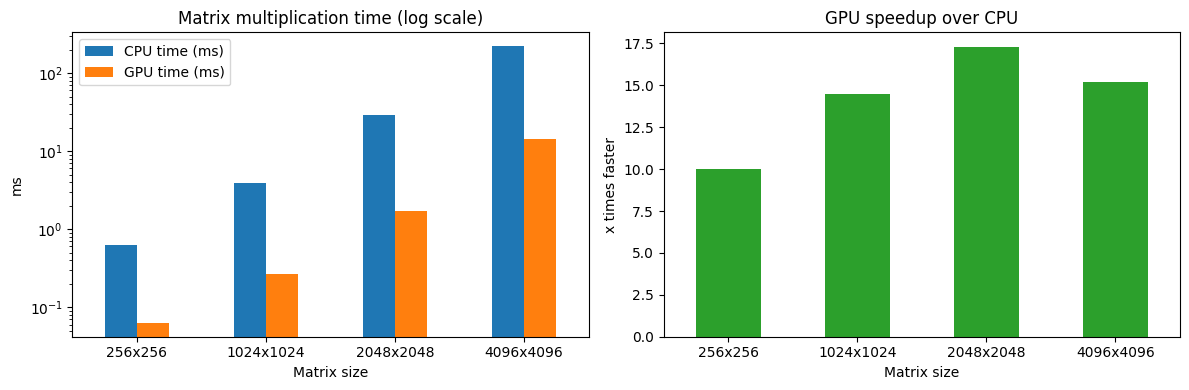

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bench.plot(x="Matrix size", y=["CPU time (ms)", "GPU time (ms)"], kind="bar", logy=True, ax=ax[0], rot=0)
ax[0].set_title("Matrix multiplication time (log scale)"); ax[0].set_ylabel("ms")
bench.plot(x="Matrix size", y="Speedup (T_CPU/T_GPU)", kind="bar", ax=ax[1], rot=0, legend=False, color="tab:green")
ax[1].set_title("GPU speedup over CPU"); ax[1].set_ylabel("x times faster")
plt.tight_layout(); plt.show()

## GPU memory usage

**Equation 2:** $M_{total}=M_{model}+M_{input}+M_{activation}+M_{gradient}$. The cell below measures the parameter and gradient parts for a small network.

In [5]:
torch.cuda.empty_cache()
before = torch.cuda.memory_allocated()

net = torch.nn.Sequential(torch.nn.Linear(1024, 4096), torch.nn.ReLU(), torch.nn.Linear(4096, 10)).to(device)
after_model = torch.cuda.memory_allocated()
x = torch.rand(256, 1024, device=device)
after_input = torch.cuda.memory_allocated()
loss = net(x).sum(); loss.backward()
after_backward = torch.cuda.memory_allocated()

params = sum(p.numel() for p in net.parameters())
mb = lambda b: round(b / 1024**2, 2)
print("Parameters:", f"{params:,}", "-> expected", mb(params * 4), "MB as float32")
print("M_model   :", mb(after_model - before), "MB")
print("M_input   :", mb(after_input - after_model), "MB")
print("M_gradient (+ kept activations):", mb(after_backward - after_input), "MB")
print("Total allocated:", mb(torch.cuda.memory_allocated()), "MB | reserved:", mb(torch.cuda.memory_reserved()), "MB")

Parameters: 4,239,370 -> expected 16.17 MB as float32
M_model   : 16.17 MB
M_input   : 1.0 MB
M_gradient (+ kept activations): 25.3 MB
Total allocated: 250.23 MB | reserved: 268.0 MB


## Step 13 – Save the environment dependencies

In [6]:
from importlib.metadata import version, PackageNotFoundError

packages = ["torch", "torchvision", "numpy", "pandas", "matplotlib", "opencv-python", "ultralytics"]
lines = []
for p in packages:
    try:
        lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError:
        pass

req = "\n".join(lines) + "\n"
with open("../requirements.txt", "w") as f:
    f.write(req)
print(req)
print("Saved ../requirements.txt (repository root)")
print("CUDA build of torch: install with  pip install -r requirements.txt --extra-index-url https://download.pytorch.org/whl/cu128")

torch==2.10.0+cu128
torchvision==0.25.0+cu128
numpy==2.2.6
pandas==2.3.3
matplotlib==3.10.8
opencv-python==4.13.0.92
ultralytics==8.4.215

Saved ../requirements.txt (repository root)
CUDA build of torch: install with  pip install -r requirements.txt --extra-index-url https://download.pytorch.org/whl/cu128


## Result
The PyTorch–CUDA development environment was configured and verified:

- CUDA-enabled PyTorch detected the NVIDIA GPU, and the device properties were displayed.
- Tensors were created on the CPU and on the GPU, and moved between them. The memory of a 1000×1000 float32 tensor was confirmed as 4 MB (*M = N × B*).
- Matrix multiplication ran on both devices with results that match. The GPU speedup *T_CPU / T_GPU* grows with matrix size.
- GPU memory for model parameters, input and gradients was measured.
- The project dependencies were saved to `requirements.txt`.